# 03 · Análisis: ¿crecimos por precio o por volumen? y ¿a cuántos mercados vendemos?

Con los datos procesados en el notebook 02 se responde la pregunta de investigación:

1. ¿Cómo se movieron los precios internacionales del café y el cacao entre 2015 y 2025?
2. ¿El valor unitario de las exportaciones peruanas sigue a esos precios?
3. ¿Cuánto del crecimiento del valor exportado se explica por precio y cuánto por volumen?
4. ¿Qué tan diversificados están los mercados de destino (Unión Europea y otros continentes)?
5. ¿Qué dicen los datos parciales de 2026?

Al final se escriben los tres hallazgos y las propuestas que usa el dashboard (`web/data/hallazgos.json`) y los gráficos en `figuras/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter, MaxNLocator

RAIZ = Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
FIGURAS = RAIZ / "figuras"
WEB_DATA = RAIZ / "web" / "data"
FIGURAS.mkdir(exist_ok=True)

ind = pd.read_csv(PROCESADOS / "indicadores_anuales.csv")
ventanas = pd.read_csv(PROCESADOS / "descomposicion_ventanas.csv")
regiones = pd.read_csv(PROCESADOS / "exportaciones_por_region.csv")
mensual = pd.read_csv(PROCESADOS / "precio_y_valor_unitario_mensual.csv")
exportaciones = pd.read_csv(PROCESADOS / "exportaciones_mensual.csv", dtype={"subpartida": str})
paises = pd.read_csv(PROCESADOS / "tabla_paises.csv").drop_duplicates("iso3").set_index("iso3").pais

ANIO_INICIO, ANIO_FIN = 2015, 2025
ANIO_PARCIAL = int(exportaciones.anio.max())
ULTIMO_MES = int(exportaciones.query("anio == @ANIO_PARCIAL").mes.max())
anual = ind.query("periodo == 'anual' and anio >= @ANIO_INICIO").set_index(["producto", "anio"])
parcial = ind.query("periodo == 'ene_ago'").set_index(["producto", "anio"])
ventana = ventanas.set_index(["producto", "desde", "hasta"])


def es(x: float, dec: int = 0) -> str:
    """Número con formato peruano: espacio para miles y coma decimal."""
    return f"{x:,.{dec}f}".replace(",", " ").replace(".", ",")


# Estilo de los gráficos: mismos colores que el dashboard (paleta validada para daltonismo)
TINTA, SECUNDARIO, REFERENCIA, REJILLA, EJE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PRECIO, VOLUMEN, VALOR = "#eb6834", "#2a78d6", "#1baf7a"
COLORES_REGION = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GRUPOS = ["Unión Europea", "Resto de Europa", "Norteamérica", "América Latina y el Caribe", "Asia y Medio Oriente", "Otros"]
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 11, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": EJE, "axes.labelcolor": SECUNDARIO, "xtick.color": SECUNDARIO,
    "ytick.color": SECUNDARIO, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": REJILLA, "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## 1. Precios internacionales, 2015–2025

Promedio anual del precio internacional (Banco Mundial, Pink Sheet) en US$/kg.

In [2]:
precios_anuales = anual.precio_int.unstack("producto").round(2)
precios_anuales

producto,Cacao,Café
anio,,
2015,3.14,3.53
2016,2.89,3.61
2017,2.03,3.32
2018,2.29,2.92
2019,2.34,2.88
2020,2.37,3.32
2021,2.43,4.51
2022,2.39,5.63
2023,3.28,4.54


In [3]:
historico = pd.read_csv(RAIZ / "datos" / "originales" / "extracto_precios_internacionales_mensual.csv")
pico = {p: mensual[mensual.producto == p].loc[lambda d: d.precio_int.idxmax()] for p in ["Café", "Cacao"]}
ultimo_precio = {p: mensual[mensual.producto == p].dropna(subset=["precio_int"]).iloc[-1] for p in ["Café", "Cacao"]}
for p, col in [("Café", "cafe_arabica"), ("Cacao", "cacao")]:
    antes = historico[historico.anio < 2021].loc[lambda d: d[col].idxmax()]
    print(f"{p}: {es(precios_anuales.loc[ANIO_INICIO, p], 2)} US$/kg en {ANIO_INICIO} → {es(precios_anuales.loc[ANIO_FIN, p], 2)} en {ANIO_FIN} "
          f"(x{es(precios_anuales.loc[ANIO_FIN, p] / precios_anuales.loc[ANIO_INICIO, p], 1)}). "
          f"Máximo mensual: {es(pico[p].precio_int, 2)} en {int(pico[p].mes):02d}/{int(pico[p].anio)} "
          f"(antes de 2021 el máximo desde {int(historico.anio.min())} era {es(antes[col], 2)}, en {int(antes.mes):02d}/{int(antes.anio)}). "
          f"Último dato: {es(ultimo_precio[p].precio_int, 2)} en {int(ultimo_precio[p].mes):02d}/{int(ultimo_precio[p].anio)}.")
assert all(pico[p].precio_int >= historico[c].max() for p, c in [("Café", "cafe_arabica"), ("Cacao", "cacao")]), "El pico no es el máximo de la serie"

Café: 3,53 US$/kg en 2015 → 8,47 en 2025 (x2,4). Máximo mensual: 9,05 en 02/2025 (antes de 2021 el máximo desde 1960 era 7,00, en 04/1977). Último dato: 7,26 en 09/2026.
Cacao: 3,14 US$/kg en 2015 → 7,80 en 2025 (x2,5). Máximo mensual: 10,75 en 01/2025 (antes de 2021 el máximo desde 1960 era 4,36, en 07/1977). Último dato: 5,92 en 09/2026.


Los dos precios estuvieron casi planos hasta 2020 y luego llegaron a los niveles nominales más altos de toda la serie del Banco Mundial
(desde 1960): el cacao entre fines de 2023 y comienzos de 2025, por las malas cosechas en África occidental, y el café arábica entre
2021 y 2025, por problemas climáticos en Brasil y otros productores. Desde 2025 los dos bajan, el cacao con mucha más fuerza.

## 2. ¿El valor unitario peruano sigue al precio internacional?

Se compara mes a mes el valor unitario FOB del producto base (café verde, cacao en grano) con el precio internacional. Se omiten los
meses con menos de 100 t exportadas, cuyo valor unitario no es representativo.

In [4]:
serie = mensual[mensual.kg_base >= 100_000].dropna(subset=["vu_base", "precio_int"])
correlaciones = pd.DataFrame({
    p: {f"{k} meses": serie[serie.producto == p].pipe(lambda d: d.vu_base.corr(d.precio_int.shift(k))) for k in range(4)}
    for p in ["Café", "Cacao"]
}).round(3)
correlaciones

,Café,Cacao
0 meses,0.947,0.971
1 meses,0.966,0.988
2 meses,0.971,0.969
3 meses,0.966,0.932


In [5]:
desfase = correlaciones.idxmax().str.extract(r"(\d)")[0].astype(int)
texto_desfase = f"{desfase.min()} a {desfase.max()} meses" if desfase.min() != desfase.max() else f"{desfase.min()} meses"
relacion = (anual.vu_base / anual.precio_int).unstack("producto").round(2)
relacion.columns = [f"{c}: valor unitario / precio" for c in relacion.columns]
relacion

,Cacao: valor unitario / precio,Café: valor unitario / precio
anio,,
2015,1.04,0.94
2016,1.13,0.87
2017,1.26,0.87
2018,1.12,0.89
2019,1.10,0.95
2020,1.15,0.90
2021,1.11,0.87
2022,1.04,0.89
2023,0.95,0.88


La correlación entre el valor unitario y el precio internacional es muy alta en los dos productos y llega a su máximo con uno o dos
meses de desfase, el tiempo entre que se pacta el precio y se embarca. En el café, el valor unitario FOB está algo por debajo del precio
indicativo, que se mide puesto en el puerto de destino (*ex-dock*). En el cacao en grano está cerca o por encima de la referencia.

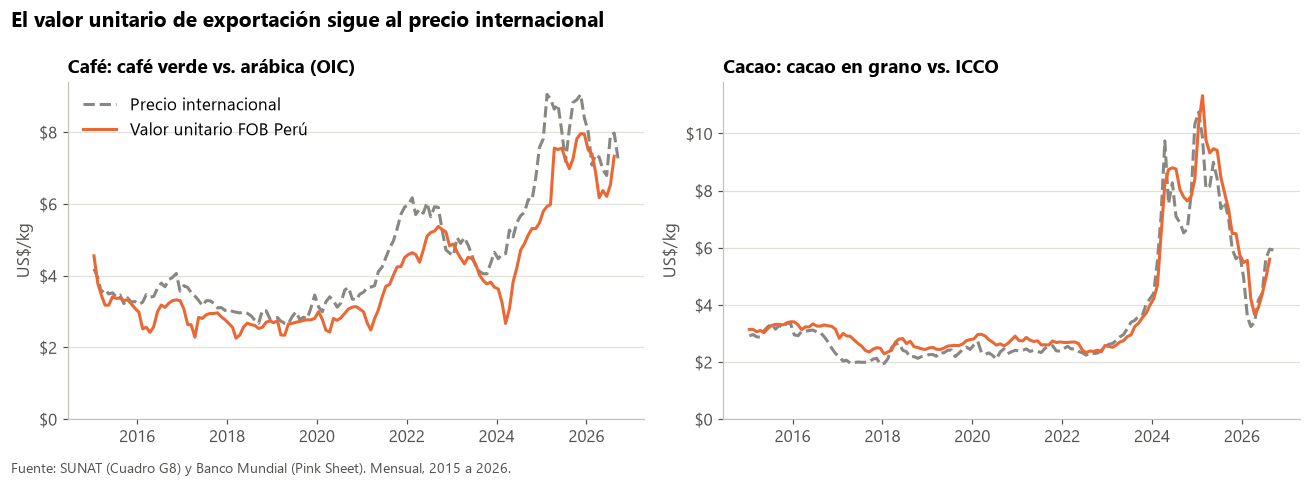

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, p in zip(ejes, ["Café", "Cacao"]):
    s = mensual[mensual.producto == p].assign(fecha=lambda d: pd.to_datetime(dict(year=d.anio, month=d.mes, day=15)))
    vu = s.vu_base.where(s.kg_base >= 100_000)
    ax.plot(s.fecha, s.precio_int, color=REFERENCIA, lw=2, ls="--", label="Precio internacional")
    ax.plot(s.fecha, vu, color=PRECIO, lw=2, label="Valor unitario FOB Perú")
    ax.set_title(f"{p}: {'café verde vs. arábica (OIC)' if p == 'Café' else 'cacao en grano vs. ICCO'}")
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.0f}"))
    ax.set_ylabel("US$/kg")
ejes[0].legend(loc="upper left")
fig.suptitle("El valor unitario de exportación sigue al precio internacional", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.02, "Fuente: SUNAT (Cuadro G8) y Banco Mundial (Pink Sheet). Mensual, 2015 a 2026.", color=SECUNDARIO, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "01_precio_vs_valor_unitario.png")
plt.show()

## 3. ¿Precio o volumen?

Descomposición del cambio del valor FOB (notebook 02, fórmula de punto medio por tipo de producto).

In [7]:
tabla_ventanas = ventanas.assign(**{c: ventanas[c] / 1e6 for c in ["fob_desde", "fob_hasta", "cambio_fob", "efecto_precio", "efecto_volumen"]})
tabla_ventanas.round(1)

,periodo,desde,hasta,producto,fob_desde,fob_hasta,cambio_fob,efecto_precio,efecto_volumen,part_precio
0,anual,2015,2025,Café,613.7,1802.0,1188.3,881.5,306.8,74.2
1,anual,2015,2025,Cacao,266.6,1618.3,1351.6,701.3,650.3,51.9
2,anual,2015,2020,Café,613.7,642.2,28.6,-60.4,88.9,-211.4
3,anual,2015,2020,Cacao,266.6,279.5,12.9,-36.1,49.0,-279.6
4,anual,2020,2025,Café,642.2,1802.0,1159.7,1009.6,150.1,87.1
5,anual,2020,2025,Cacao,279.5,1618.3,1338.7,798.3,540.4,59.6
6,anual,2023,2025,Café,819.7,1802.0,982.3,769.4,212.9,78.3
7,anual,2023,2025,Cacao,427.7,1618.3,1190.6,793.5,397.0,66.7
8,anual,2024,2025,Café,1101.7,1802.0,700.2,675.6,24.6,96.5
9,anual,2024,2025,Cacao,1280.5,1618.3,337.8,221.5,116.3,65.6


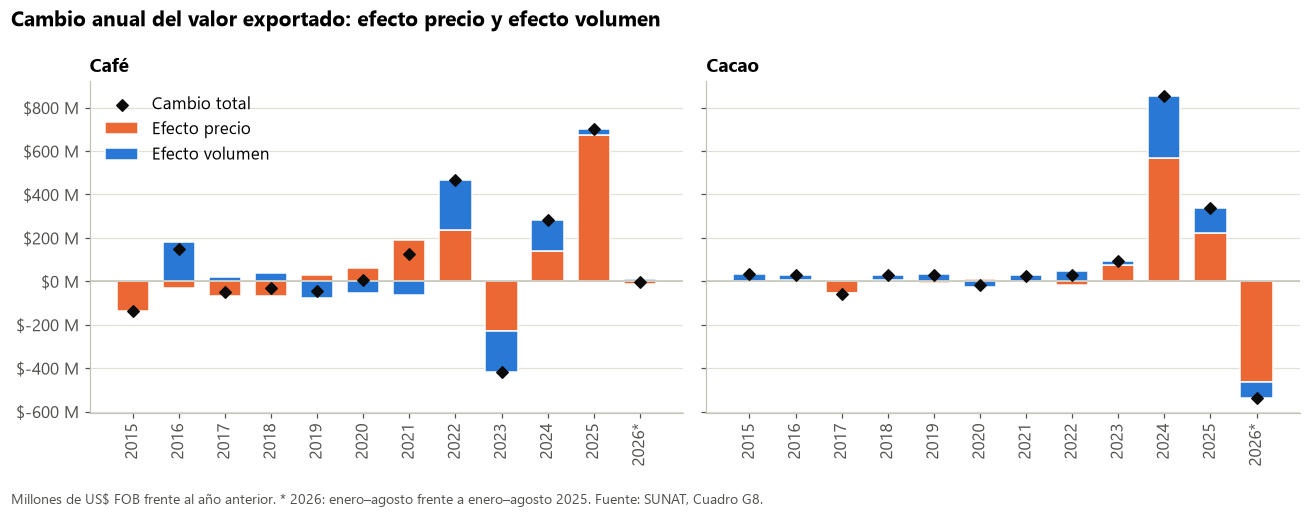

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, p in zip(ejes, ["Café", "Cacao"]):
    a = anual.loc[p]
    x = [str(v) for v in a.index] + [f"{ANIO_PARCIAL}*"]
    ep = list(a.efecto_precio / 1e6) + [parcial.loc[(p, ANIO_PARCIAL), "efecto_precio"] / 1e6]
    ev = list(a.efecto_volumen / 1e6) + [parcial.loc[(p, ANIO_PARCIAL), "efecto_volumen"] / 1e6]
    pos = [max(v, 0) for v in ep]
    neg = [min(v, 0) for v in ep]
    ax.bar(x, ep, color=PRECIO, width=0.7, label="Efecto precio", edgecolor="white", linewidth=1)
    ax.bar(x, ev, bottom=[pp if v >= 0 else nn for v, pp, nn in zip(ev, pos, neg)], color=VOLUMEN, width=0.7,
           label="Efecto volumen", edgecolor="white", linewidth=1)
    ax.scatter(x, [a_ + b_ for a_, b_ in zip(ep, ev)], marker="D", s=28, color=TINTA, zorder=3, label="Cambio total")
    ax.axhline(0, color=EJE, lw=1)
    ax.set_title(p)
    ax.tick_params(axis="x", rotation=90)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f} M"))
ejes[0].legend(loc="upper left")
fig.suptitle("Cambio anual del valor exportado: efecto precio y efecto volumen", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.04, f"Millones de US$ FOB frente al año anterior. * {ANIO_PARCIAL}: enero–agosto frente a enero–agosto {ANIO_PARCIAL - 1}. "
         "Fuente: SUNAT, Cuadro G8.", color=SECUNDARIO, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "02_descomposicion_precio_volumen.png")
plt.show()

## 4. Diversificación de mercados

### 4.1 Regiones de destino

Las regiones pequeñas (África, Oceanía y destinos sin país) se juntan en "Otros".

In [9]:
def agrupar(region: str) -> str:
    return region if region in GRUPOS else "Otros"


reg = regiones.assign(grupo=regiones.region.map(agrupar)).groupby(["periodo", "producto", "anio", "grupo"]).fob.sum()
reg_part = (reg / reg.groupby(level=["periodo", "producto", "anio"]).transform("sum") * 100).unstack("grupo")[GRUPOS].fillna(0)
reg_part.loc["anual"].query("anio in [@ANIO_INICIO, @ANIO_FIN]").round(1)

grupo          Unión Europea  Resto de Europa  Norteamérica  \
producto anio                                                 
Cacao    2015           65.6              5.3          15.9   
         2025           40.3              1.1          23.8   
Café     2015           54.4              3.3          30.5   
         2025           40.4              4.1          43.0   

grupo          América Latina y el Caribe  Asia y Medio Oriente  Otros  
producto anio                                                           
Cacao    2015                         8.1                   4.0    1.1  
         2025                        19.6                  14.2    1.1  
Café     2015                         4.0                   6.4    1.4  
         2025                         6.8                   4.2    1.6

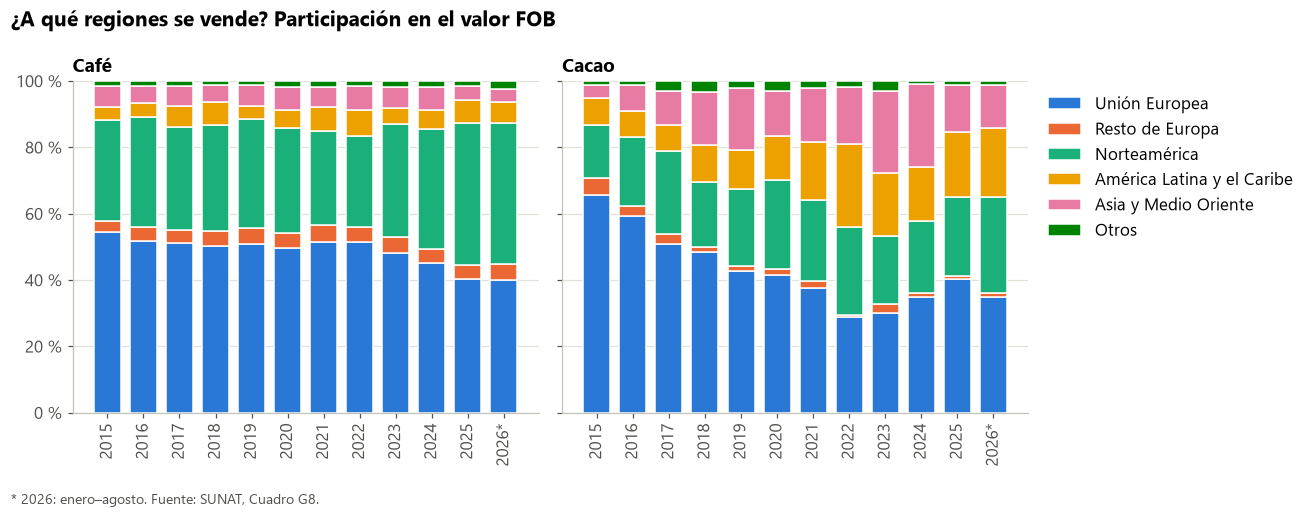

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, p in zip(ejes, ["Café", "Cacao"]):
    t = pd.concat([reg_part.loc[("anual", p)].loc[ANIO_INICIO:ANIO_FIN], reg_part.loc[("ene_ago", p)].loc[[ANIO_PARCIAL]]])
    x = [str(v) for v in t.index[:-1]] + [f"{ANIO_PARCIAL}*"]
    abajo = pd.Series(0.0, index=t.index)
    for g, color in zip(GRUPOS, COLORES_REGION):
        ax.bar(x, t[g], bottom=abajo, color=color, width=0.75, label=g, edgecolor="white", linewidth=1)
        abajo += t[g]
    ax.set_title(p)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=90)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ejes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("¿A qué regiones se vende? Participación en el valor FOB", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, -0.04, f"* {ANIO_PARCIAL}: enero–agosto. Fuente: SUNAT, Cuadro G8.", color=SECUNDARIO, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "03_destinos_por_region.png")
plt.show()

### 4.2 Concentración por país: mercados equivalentes

In [11]:
diversif = anual[["mercados_equivalentes", "ihh", "n_destinos", "principal_iso3", "principal_part", "part_ue"]].copy()
diversif["principal"] = diversif.principal_iso3.map(paises)
diversif.drop(columns="principal_iso3").round(1).unstack("producto").loc[[2015, 2019, 2022, 2023, 2024, 2025]]

mercados_equivalentes          ihh         n_destinos       \
producto                 Cacao Café   Cacao    Café      Cacao Café   
anio                                                                  
2015                       5.9  5.9  1689.4  1705.3         57   46   
2019                       7.6  6.7  1324.0  1497.4         69   52   
2022                       8.9  7.9  1123.8  1273.8         69   57   
2023                      10.2  7.3   984.1  1363.5         71   60   
2024                      10.4  6.9   965.6  1446.0         70   56   
2025                      10.4  6.1   961.9  1652.2         70   56   

         principal_part       part_ue             principal                  
producto          Cacao  Café   Cacao  Café           Cacao            Café  
anio                                                                         
2015               35.4  29.0    65.6  54.4    Países Bajos        Alemania  
2019               23.3  27.2    42.7  51.0    Países Bajos  Estados Unidos  
2022               23.9  23.0    29.0  51.4  Estados Unidos  Estados Unidos  
2023               18.6  28.1    30.1  48.2  Estados Unidos  Estados Unidos  
2024               19.7  28.2    34.8  45.1  Estados Unidos  Estados Unidos  
2025               20.7  33.2    40.3  40.4  Estados Unidos  Estados Unidos

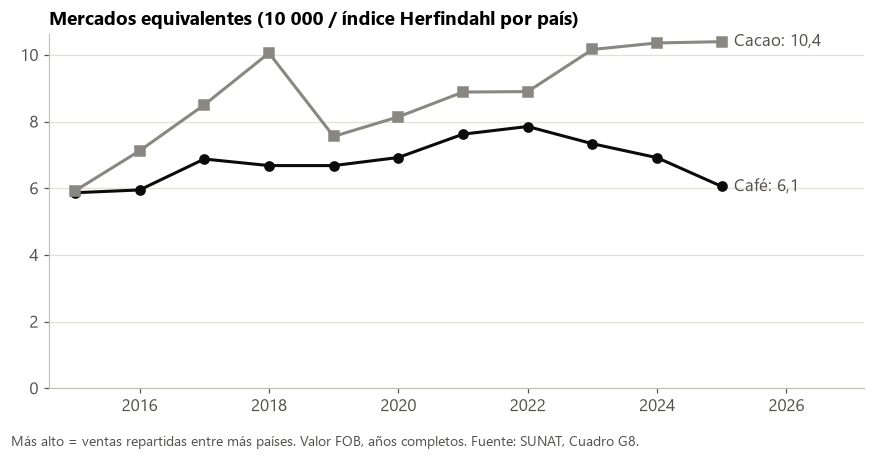

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for p, color, marca in [("Café", TINTA, "o"), ("Cacao", REFERENCIA, "s")]:
    s = anual.loc[p].mercados_equivalentes
    ax.plot(s.index, s, color=color, lw=2, marker=marca, ms=6)
    ax.annotate(f"{p}: {es(s.iloc[-1], 1)}", (s.index[-1], s.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=SECUNDARIO, fontsize=11)
ax.set_xlim(ANIO_INICIO - 0.4, ANIO_FIN + 2.2)
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Mercados equivalentes (10 000 / índice Herfindahl por país)")
fig.text(0.01, -0.03, "Más alto = ventas repartidas entre más países. Valor FOB, años completos. Fuente: SUNAT, Cuadro G8.",
         color=SECUNDARIO, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "04_mercados_equivalentes.png")
plt.show()

El cacao pasó de depender de Europa a vender en todos los continentes: los mercados equivalentes casi se duplicaron. El café fue en
sentido contrario en los últimos años: se concentra más en Estados Unidos y Norteamérica, mientras baja la parte de la Unión Europea.

### 4.3 ¿Cuánto pesa el producto base?

In [13]:
comp = (exportaciones.query("anio in [@ANIO_INICIO, @ANIO_FIN]").groupby(["producto", "subgrupo", "anio"]).fob_usd.sum()
        .unstack("anio").pipe(lambda t: t / t.groupby(level="producto").transform("sum") * 100).round(1))
comp

anio                                       2015  2025
producto subgrupo                                    
Cacao    Cacao en grano                    72.1  60.1
         Cacao en polvo                     4.0   6.5
         Chocolate y preparaciones          5.8   6.1
         Cáscara y residuos de cacao        0.0   0.2
         Manteca de cacao                  16.1  20.4
         Pasta de cacao                     1.9   6.7
Café     Café tostado                       0.3   0.1
         Café verde                        99.2  99.8
         Café verde descafeinado            0.1   0.0
         Cáscara, cascarilla y sucedáneos   0.4   0.1

## 5. Lo que va de 2026 (enero–agosto)

In [14]:
cols = ["fob", "kg", "vu_base", "precio_int", "var_fob", "var_kg", "var_vu_base", "var_precio_int", "efecto_precio", "efecto_volumen"]
parcial.loc[(slice(None), [ANIO_PARCIAL - 1, ANIO_PARCIAL]), cols].assign(
    fob=lambda d: d.fob / 1e6, kg=lambda d: d.kg / 1e6, efecto_precio=lambda d: d.efecto_precio / 1e6,
    efecto_volumen=lambda d: d.efecto_volumen / 1e6).round(2)

fob      kg  vu_base  precio_int  var_fob  var_kg  \
producto anio                                                          
Cacao    2025  1115.37  114.00     9.02        8.65    40.76    8.18   
         2026   579.22  101.72     4.70        4.42   -48.07  -10.78   
Café     2025   700.05   99.73     7.01        8.31    26.49  -25.84   
         2026   697.12  101.39     6.86        7.42    -0.42    1.66   

               var_vu_base  var_precio_int  efecto_precio  efecto_volumen  
producto anio                                                              
Cacao    2025        17.24           22.33         272.23           50.75  
         2026       -47.89          -48.96        -464.43          -71.72  
Café     2025        70.40           62.34         339.60         -193.00  
         2026        -2.09          -10.64         -14.45           11.52

## 6. Hallazgos y propuestas

Las cifras se calculan aquí y se escriben en `web/data/hallazgos.json`, que el dashboard muestra tal cual.

In [15]:
c, k = anual.loc["Café"], anual.loc["Cacao"]
vc, vk = ventana.loc[("Café", 2015, 2025)], ventana.loc[("Cacao", 2015, 2025)]
c25 = ventana.loc[("Café", 2024, 2025)]
k23 = ventana.loc[("Cacao", 2023, 2025)]
k26, c26 = parcial.loc[("Cacao", ANIO_PARCIAL)], parcial.loc[("Café", ANIO_PARCIAL)]
k26v = ventana.loc[("Cacao", ANIO_PARCIAL - 1, ANIO_PARCIAL)]
rp = reg_part.loc["anual"]

h1 = {
    "titulo": f"Café: {es(vc.part_precio)} % del crecimiento del valor vino del precio",
    "texto": (
        f"Entre {ANIO_INICIO} y {ANIO_FIN}, el café exportado pasó de US$ {es(c.fob[ANIO_INICIO] / 1e6)} a US$ {es(c.fob[ANIO_FIN] / 1e6)} "
        f"millones, pero el volumen solo creció {es((c.kg[ANIO_FIN] / c.kg[ANIO_INICIO] - 1) * 100)} % "
        f"({es(c.kg[ANIO_INICIO] / 1e6, 1)} → {es(c.kg[ANIO_FIN] / 1e6, 1)} mil t). De los US$ {es(vc.cambio_fob / 1e6)} millones adicionales, "
        f"US$ {es(vc.efecto_precio / 1e6)} millones se explican por mejor precio. Solo en {ANIO_FIN}, el valor subió "
        f"US$ {es(c25.cambio_fob / 1e6)} millones con casi el mismo volumen ({es(c.var_kg[ANIO_FIN], 1)} %): el "
        f"{es(c25.part_precio)} % fue precio, con el arábica en su nivel nominal más alto desde 1960 ({es(pico['Café'].precio_int, 2)} US$/kg "
        f"en {int(pico['Café'].mes):02d}/{int(pico['Café'].anio)})."
    ),
}
h2 = {
    "titulo": "Cacao: creció en precio y en volumen, y ya muestra lo rápido que se revierte el precio",
    "texto": (
        f"El cacao multiplicó su valor por {es(k.fob[ANIO_FIN] / k.fob[ANIO_INICIO], 1)} entre {ANIO_INICIO} y {ANIO_FIN} "
        f"(US$ {es(k.fob[ANIO_INICIO] / 1e6)} → {es(k.fob[ANIO_FIN] / 1e6)} millones). Aquí el volumen sí acompañó: se multiplicó por "
        f"{es(k.kg[ANIO_FIN] / k.kg[ANIO_INICIO], 1)}, y el precio explica el {es(vk.part_precio)} % del aumento. Pero el valor unitario sigue "
        f"al precio internacional con uno o dos meses de desfase (correlación {es(correlaciones['Cacao'].max(), 2)}). En enero–agosto de "
        f"{ANIO_PARCIAL}, el precio internacional promedió {es(k26.precio_int, 2)} US$/kg, {es(-k26.var_precio_int)} % menos que un año "
        f"antes, y el valor exportado cayó {es(-k26.var_fob)} % (US$ {es(-k26v.cambio_fob / 1e6)} millones menos), aunque el volumen bajó "
        f"solo {es(-k26.var_kg)} %."
    ),
}
h3 = {
    "titulo": "Diversificación: el cacao se abrió al mundo; el café se concentra en Norteamérica",
    "texto": (
        f"En {ANIO_INICIO}, la Unión Europea compraba el {es(rp.loc[('Cacao', ANIO_INICIO), 'Unión Europea'])} % del cacao; en {ANIO_FIN}, el "
        f"{es(rp.loc[('Cacao', ANIO_FIN), 'Unión Europea'])} %, mientras crecían Norteamérica "
        f"({es(rp.loc[('Cacao', ANIO_FIN), 'Norteamérica'])} %), América Latina ({es(rp.loc[('Cacao', ANIO_FIN), 'América Latina y el Caribe'])} %) "
        f"y Asia ({es(rp.loc[('Cacao', ANIO_FIN), 'Asia y Medio Oriente'])} %). Sus mercados equivalentes subieron de "
        f"{es(k.mercados_equivalentes[ANIO_INICIO], 1)} a {es(k.mercados_equivalentes[ANIO_FIN], 1)}. En café, la UE bajó de "
        f"{es(rp.loc[('Café', ANIO_INICIO), 'Unión Europea'])} % a {es(rp.loc[('Café', ANIO_FIN), 'Unión Europea'])} % y Norteamérica subió de "
        f"{es(rp.loc[('Café', ANIO_INICIO), 'Norteamérica'])} % a {es(rp.loc[('Café', ANIO_FIN), 'Norteamérica'])} %; Estados Unidos ya compra el "
        f"{es(c.principal_part[ANIO_FIN])} %. Sus mercados equivalentes cayeron de {es(c.mercados_equivalentes[2022], 1)} (2022) a "
        f"{es(c.mercados_equivalentes[ANIO_FIN], 1)}."
    ),
}
hallazgos = [h1, h2, h3]

propuestas = [
    {
        "titulo": "Comunicar valor y volumen juntos",
        "texto": (
            "Un récord de valor exportado con el volumen casi igual no es un salto productivo: es una mejora de precio. Reportar siempre el "
            "valor, el volumen y el valor unitario evita expectativas que luego se frustran cuando el precio corrige."
        ),
    },
    {
        "titulo": "Usar los buenos años para invertir en productividad y calidad",
        "texto": (
            f"El precio no depende del Perú; la productividad sí. En café el volumen apenas creció {es((c.kg[ANIO_FIN] / c.kg[ANIO_INICIO] - 1) * 100)} % "
            "en diez años. Los ingresos extraordinarios pueden financiar renovación de plantaciones, asistencia técnica y mejoras de calidad, "
            "que sostienen el valor cuando el precio baja."
        ),
    },
    {
        "titulo": "Gestionar el riesgo de precio",
        "texto": (
            f"El valor unitario sigue al precio internacional con {texto_desfase} de desfase. Contratos con precio "
            "fijado, coberturas a través de cooperativas y exportadores, y fondos de reserva en las organizaciones de productores ayudan a "
            "suavizar caídas como la del cacao en 2026."
        ),
    },
    {
        "titulo": "Seguir la diversificación con un indicador simple",
        "texto": (
            "El cacao muestra que diversificar es posible. Para el café, un indicador de seguimiento anual podría ser sostener o recuperar los "
            f"mercados equivalentes (hoy {es(c.mercados_equivalentes[ANIO_FIN], 1)}) y crecer en mercados donde aún pesa poco, como Asia "
            f"({es(rp.loc[('Café', ANIO_FIN), 'Asia y Medio Oriente'])} %). Diversificar no es dejar Europa: es depender menos de un solo comprador."
        ),
    },
]

(WEB_DATA / "hallazgos.json").write_text(
    json.dumps({"hallazgos": hallazgos, "propuestas": propuestas}, ensure_ascii=False, indent=2), encoding="utf-8")
for h in hallazgos + propuestas:
    print(f"■ {h['titulo']}\n  {h['texto']}\n")

■ Café: 74 % del crecimiento del valor vino del precio
  Entre 2015 y 2025, el café exportado pasó de US$ 614 a US$ 1 802 millones, pero el volumen solo creció 31 % (185,1 → 242,5 mil t). De los US$ 1 188 millones adicionales, US$ 881 millones se explican por mejor precio. Solo en 2025, el valor subió US$ 700 millones con casi el mismo volumen (1,7 %): el 96 % fue precio, con el arábica en su nivel nominal más alto desde 1960 (9,05 US$/kg en 02/2025).

■ Cacao: creció en precio y en volumen, y ya muestra lo rápido que se revierte el precio
  El cacao multiplicó su valor por 6,1 entre 2015 y 2025 (US$ 267 → 1 618 millones). Aquí el volumen sí acompañó: se multiplicó por 2,4, y el precio explica el 52 % del aumento. Pero el valor unitario sigue al precio internacional con uno o dos meses de desfase (correlación 0,99). En enero–agosto de 2026, el precio internacional promedió 4,42 US$/kg, 49 % menos que un año antes, y el valor exportado cayó 48 % (US$ 536 millones menos), aunque el volum